# Analysis: which industries sponsor League of Legends organizations, 2019–2026?

**Michael Chow**

**Question.** Which industries sponsored top League of Legends organizations from 2019 to 2026, and which categories were prominent over the years? My proposal expected energy drink and hardware brands early on, a crypto and Web3 surge in 2021–2022, a drop after the FTX crash (November 2022), and more betting sponsors from late 2024.

**Data.** `data/clean/sponsors_clean.csv`, made by `collect_and_clean.ipynb`. Run that notebook first.

**How I count.** A team has up to two captures a year (early and late). I count each sponsor **once per team per year**, so a sponsor that stayed all year is not counted twice. I call one sponsor of one team in one year a **sponsor slot**.

**Why I use percentages.** Some years have data for 4 teams and others for 9, so raw counts would make busy years look bigger. Instead I use (1) each industry's percentage of a year's sponsor slots and (2) the percentage of teams with at least one sponsor in an industry.

The three analyses from my proposal:

1. Each industry's share of sponsor slots by year (Figure 1).
2. Crypto and betting sponsors over time and by region (Figure 2).
3. New sponsors each year and which industries they come from.

In [2]:
# What this cell does: loads the libraries and the clean data, and sets up names and colors for the charts.
import os

import matplotlib.pyplot as plt
import pandas as pd

sponsors = pd.read_csv("data/clean/sponsors_clean.csv")
os.makedirs("figures", exist_ok=True)

YEARS = list(range(2019, 2027))

# Readable names for each industry code (in the order the charts stack them)
LABELS = {
    "crypto_web3": "Crypto / Web3",
    "betting": "Betting",
    "finance": "Finance",
    "pc_hardware_peripherals": "PC hardware",
    "telecom_tech": "Telecom & tech",
    "energy_drink_food": "Energy drinks & food",
    "automotive": "Automotive",
    "apparel": "Apparel",
    "cosmetics": "Cosmetics",
    "supplements": "Supplements",
    "other": "Other",
}
# Crypto and betting get bright colors; the other industries get softer ones
COLORS = {
    "crypto_web3": "#D55E00", "betting": "#7B3294", "finance": "#E7B9A0",
    "pc_hardware_peripherals": "#0F4C81", "telecom_tech": "#6A9AC4", "energy_drink_food": "#A9C6DE",
    "automotive": "#B8B8B8", "apparel": "#D4D4D4", "cosmetics": "#C9BBA8", "supplements": "#DCD3C4",
    "other": "#EBEBEB",
}

print("Rows:", len(sponsors))
print("Teams:", sponsors["org"].nunique())
print("Distinct sponsors:", sponsors["sponsor_key"].nunique())
print("Industries in the data:", sorted(sponsors["industry"].unique()))

Rows: 736
Teams: 9
Distinct sponsors: 151
Industries in the data: ['apparel', 'automotive', 'betting', 'cosmetics', 'crypto_web3', 'energy_drink_food', 'finance', 'other', 'pc_hardware_peripherals', 'supplements', 'telecom_tech']


## Coverage: how many sponsors were found for each team and year?

A blank cell means no capture, or a page where no sponsors could be read. A team counts as **observed** in a year when at least one sponsor was found.

In [4]:
# What this cell does: keeps one row per team + year + sponsor (removing the early/late duplicate),
# then counts sponsors for each team and year, and how many teams have data each year.
team_year = sponsors.drop_duplicates(subset=["org", "year", "sponsor_key"])
print("Sponsor slots (one sponsor of one team in one year):", len(team_year))

coverage = pd.crosstab(team_year["org"], team_year["year"])
print(coverage.replace(0, ""))

teams_observed = team_year.groupby("year")["org"].nunique()
print("\nTeams with data each year:")
print(teams_observed)

Sponsor slots (one sponsor of one team in one year): 475
year          2019 2020 2021  2022  2023 2024 2025 2026
org                                                    
Cloud9          10   10   11    14     7    7    4    4
FlyQuest         1    1          1     2         2    2
Fnatic          11         2     5     4    5    4     
G2 Esports       8   15   12    14    13   14   12   12
Gen.G                     12    14    13   11          
SK Gaming                       10    11   13   15   15
T1                              14     2    1    1     
Team Liquid      6    5   10    12    10   10   15   14
Team Vitality                   16    11   10    7   10

Teams with data each year:
year
2019    5
2020    4
2021    5
2022    9
2023    9
2024    8
2025    8
2026    6
Name: org, dtype: int64


## 1. Industry share of sponsor slots by year

In [6]:
# What this cell does: makes a table of each industry's percentage of sponsor slots in each year.
# normalize="index" turns each row (year) into percentages that add up to 100.
industry_order = [code for code in LABELS if code in sponsors["industry"].unique()]

share = pd.crosstab(team_year["year"], team_year["industry"], normalize="index") * 100
share = share[industry_order]   # put the columns in chart order

table1 = share.round(1).rename(columns=LABELS)
table1["Sponsor slots"] = team_year.groupby("year").size()
table1["Teams with data"] = teams_observed
table1

industry,Crypto / Web3,Betting,Finance,PC hardware,Telecom & tech,Energy drinks & food,Automotive,Apparel,Cosmetics,Supplements,Other,Sponsor slots,Teams with data
year,,,,,,,,,,,,,
2019,2.8,5.6,5.6,36.1,11.1,16.7,5.6,2.8,0.0,0.0,13.9,36,5
2020,3.2,0.0,9.7,32.3,9.7,22.6,9.7,3.2,0.0,0.0,9.7,31,4
2021,6.4,0.0,12.8,29.8,10.6,14.9,8.5,10.6,0.0,0.0,6.4,47,5
2022,8.0,2.0,8.0,33.0,11.0,11.0,7.0,8.0,1.0,1.0,10.0,100,9
2023,8.2,1.4,9.6,32.9,11.0,12.3,6.8,4.1,1.4,1.4,11.0,73,9
2024,7.0,4.2,7.0,32.4,8.5,15.5,7.0,7.0,0.0,0.0,11.3,71,8
2025,3.3,8.3,8.3,31.7,6.7,11.7,8.3,8.3,3.3,0.0,10.0,60,8
2026,1.8,7.0,8.8,29.8,7.0,10.5,8.8,8.8,3.5,0.0,14.0,57,6


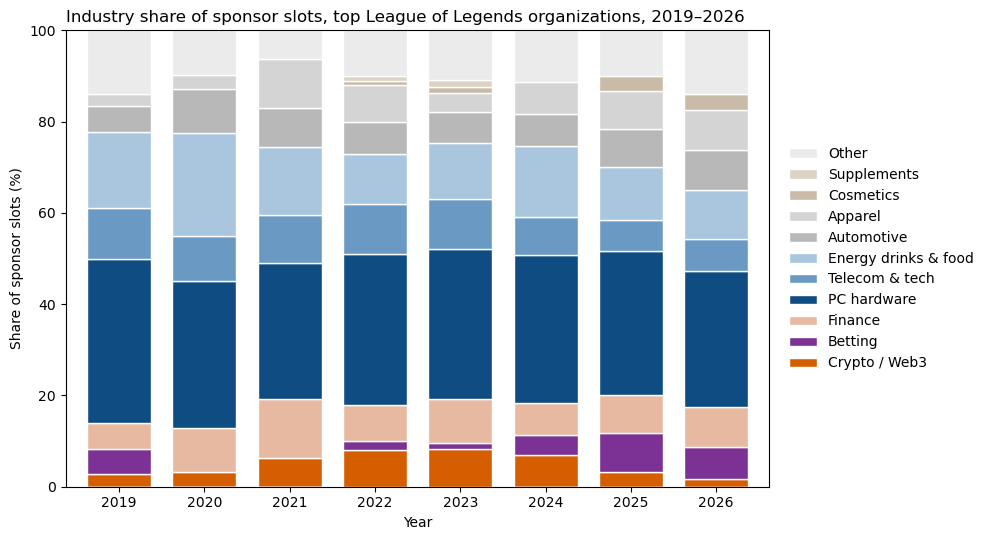

In [7]:
# What this cell does: draws Figure 1, a 100% stacked bar chart of the table above, and saves it.
ax = share.plot(kind="bar", stacked=True, figsize=(10, 5.5), width=0.75,
                color=[COLORS[code] for code in industry_order], edgecolor="white")

ax.set_title("Industry share of sponsor slots, top League of Legends organizations, 2019–2026", loc="left")
ax.set_xlabel("Year")
ax.set_ylabel("Share of sponsor slots (%)")
ax.set_xticklabels(YEARS, rotation=0)
ax.set_ylim(0, 100)

# Legend outside the plot, in the same order as the stacked colors (top to bottom)
handles, names = ax.get_legend_handles_labels()
ax.legend(handles[::-1], [LABELS[n] for n in names[::-1]], loc="center left",
          bbox_to_anchor=(1.01, 0.5), frameon=False)

plt.tight_layout()
plt.savefig("figures/fig1_industry_share_by_year.png", dpi=200, bbox_inches="tight")
plt.show()

**Figure 1.** Each bar splits one year's sponsor slots across industries, with crypto/Web3 and betting at the bottom so their rise and fall is easy to compare.

## 2. Crypto and betting sponsors over time

For each year: how many teams had at least one crypto sponsor or one betting sponsor, and what percentage of the observed teams that is.

In [10]:
# What this cell does: counts the teams with at least one crypto (or betting) sponsor each year,
# then divides by the number of teams with data that year to get a percentage.
crypto = team_year[team_year["industry"] == "crypto_web3"]
betting = team_year[team_year["industry"] == "betting"]

table2 = pd.DataFrame({
    "Teams with data": teams_observed,
    "Teams with crypto": crypto.groupby("year")["org"].nunique(),
    "Teams with betting": betting.groupby("year")["org"].nunique(),
}).reindex(YEARS).fillna(0).astype(int)

table2["% with crypto"] = (table2["Teams with crypto"] / table2["Teams with data"] * 100).round(0)
table2["% with betting"] = (table2["Teams with betting"] / table2["Teams with data"] * 100).round(0)
table2

,Teams with data,Teams with crypto,Teams with betting,% with crypto,% with betting
year,,,,,
2019,5,1,1,20.0,20.0
2020,4,1,0,25.0,0.0
2021,5,3,0,60.0,0.0
2022,9,5,2,56.0,22.0
2023,9,5,1,56.0,11.0
2024,8,4,3,50.0,38.0
2025,8,1,4,12.0,50.0
2026,6,1,2,17.0,33.0


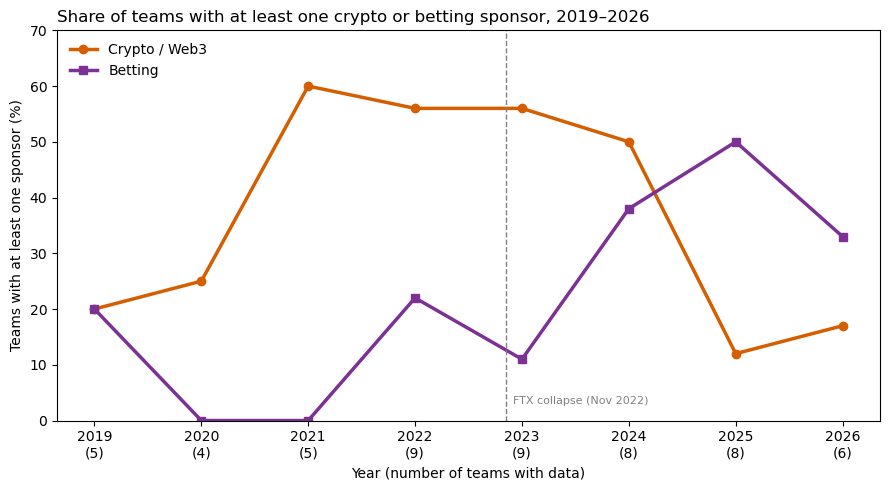

In [11]:
# What this cell does: draws Figure 2, one line for crypto and one for betting, and saves it.
plt.figure(figsize=(9, 5))
plt.plot(YEARS, table2["% with crypto"], marker="o", linewidth=2.5, color=COLORS["crypto_web3"], label="Crypto / Web3")
plt.plot(YEARS, table2["% with betting"], marker="s", linewidth=2.5, color=COLORS["betting"], label="Betting")

# Dashed line for the FTX collapse (November 2022)
plt.axvline(2022.85, color="gray", linestyle="--", linewidth=1)
plt.text(2022.92, 3, "FTX collapse (Nov 2022)", fontsize=8, color="gray")

plt.title("Share of teams with at least one crypto or betting sponsor, 2019–2026", loc="left")
plt.xlabel("Year (number of teams with data)")
plt.ylabel("Teams with at least one sponsor (%)")
plt.xticks(YEARS, [f"{year}\n({table2.loc[year, 'Teams with data']})" for year in YEARS])
plt.ylim(0, 70)
plt.legend(loc="upper left", frameon=False)

plt.tight_layout()
plt.savefig("figures/fig2_crypto_betting_teams.png", dpi=200, bbox_inches="tight")
plt.show()

**Figure 2.** The percentage of teams (number with data under each year) that list at least one crypto/Web3 or betting sponsor on their partner page; the dashed line marks the FTX collapse in November 2022.

In [13]:
# What this cell does: counts crypto and betting sponsor slots by region and year.
crypto_betting = team_year[team_year["industry"].isin(["crypto_web3", "betting"])]
pd.crosstab([crypto_betting["region"], crypto_betting["industry"]], crypto_betting["year"])

year                       2019  2020  2021  2022  2023  2024  2025  2026
region        industry                                                   
Europe        betting         2     0     0     1     0     2     4     3
              crypto_web3     1     1     2     5     4     2     0     0
North America betting         0     0     0     1     1     1     1     1
              crypto_web3     0     0     1     3     2     3     2     1

In [14]:
# What this cell does: lists every crypto and betting sponsor, which team had it, and in which years.
crypto_betting.groupby(["industry", "sponsor_name", "org"])["year"].apply(lambda years: sorted(years.unique()))

industry     sponsor_name     org          
betting      BC.GAME          Cloud9                       [2022, 2023, 2024]
             Betify           Fnatic                             [2024, 2025]
             Betpanda         G2 Esports                         [2025, 2026]
             Duelbits         Team Liquid                        [2025, 2026]
             GG.BET           Team Vitality                [2022, 2024, 2025]
             Letou            Fnatic                                   [2019]
             Rivalry          Fnatic                                   [2019]
             Skin.Club        G2 Esports                               [2026]
             Skinrave         G2 Esports                               [2025]
             Winamax          G2 Esports                               [2026]
crypto_web3  Blockchain.com   Cloud9                                   [2022]
             Bondly           G2 Esports                         [2021, 2022]
             Coinbas

## 3. New sponsors each year

A sponsor is **new** in the first year it appears on a team's page. Each team's first year with data is left out, because every sponsor would look new that year.

In [16]:
# What this cell does: finds the first year each sponsor appears for each team,
# keeps the ones that appear after the team's own first year, and counts them by year and industry.
first_seen = team_year.groupby(["org", "sponsor_key", "industry"], as_index=False)["year"].min()
team_start = team_year.groupby("org")["year"].min()

first_seen["team_first_year"] = first_seen["org"].map(team_start)
new_sponsors = first_seen[first_seen["year"] > first_seen["team_first_year"]]

table3 = pd.crosstab(new_sponsors["year"], new_sponsors["industry"])
table3 = table3[[code for code in industry_order if code in table3.columns]].rename(columns=LABELS)
table3["Total new"] = table3.sum(axis=1)
table3

industry,Crypto / Web3,Betting,Finance,PC hardware,Telecom & tech,Energy drinks & food,Automotive,Apparel,Cosmetics,Supplements,Other,Total new
year,,,,,,,,,,,,
2020,0,0,1,3,0,3,1,0,0,0,2,10
2021,3,0,1,3,1,1,0,3,0,0,0,12
2022,3,1,0,3,1,0,1,0,0,1,3,13
2023,0,0,2,3,2,2,2,1,0,0,0,12
2024,1,1,1,4,2,2,0,2,0,0,2,15
2025,0,3,0,4,0,0,1,1,2,0,2,13
2026,0,2,1,3,1,1,2,1,0,0,4,15


## 4. Checking the expectations from the proposal

In [18]:
# What this cell does: prints the numbers that answer each expectation in my proposal.
print("Crypto: % of teams with a crypto sponsor each year")
print(table2["% with crypto"].to_dict())

print("\nBetting: % of teams with a betting sponsor each year")
print(table2["% with betting"].to_dict())

print("\nCrypto sponsors still on a page in 2024 or later:")
print(crypto[crypto["year"] >= 2024][["org", "sponsor_name", "year"]].to_string(index=False))

hardware_food = share["pc_hardware_peripherals"] + share["energy_drink_food"]
print("\nPC hardware + energy drinks & food, % of sponsor slots each year")
print(hardware_food.round(0).to_dict())

Crypto: % of teams with a crypto sponsor each year
{2019: 20.0, 2020: 25.0, 2021: 60.0, 2022: 56.0, 2023: 56.0, 2024: 50.0, 2025: 12.0, 2026: 17.0}

Betting: % of teams with a betting sponsor each year
{2019: 20.0, 2020: 0.0, 2021: 0.0, 2022: 22.0, 2023: 11.0, 2024: 38.0, 2025: 50.0, 2026: 33.0}

Crypto sponsors still on a page in 2024 or later:
          org sponsor_name  year
       Cloud9      Polygon  2024
   G2 Esports     Metaplex  2024
  Team Liquid     Coinbase  2024
  Team Liquid          Sui  2024
  Team Liquid     Coinbase  2025
  Team Liquid          Sui  2025
  Team Liquid          Sui  2026
Team Vitality        Tezos  2024

PC hardware + energy drinks & food, % of sponsor slots each year
{2019: 53.0, 2020: 55.0, 2021: 45.0, 2022: 44.0, 2023: 45.0, 2024: 48.0, 2025: 43.0, 2026: 40.0}


## Export for Power BI

One clean table, with one row per team + year + sponsor and readable column names, so Power BI counts each sponsor once per team per year.

In [20]:
# What this cell does: saves the team-year table with readable column names for Power BI.
os.makedirs("data/clean/for_charts", exist_ok=True)

powerbi = team_year[["org", "region", "year", "sponsor_name", "sponsor_domain", "industry"]].copy()
powerbi["industry"] = powerbi["industry"].map(LABELS)

# New this year = the sponsor's first year with this team, and not the team's own first year with data
first_year_with_team = team_year.groupby(["org", "sponsor_key"])["year"].transform("min")
powerbi["new_this_year"] = (team_year["year"] == first_year_with_team) & (team_year["year"] > team_year["org"].map(team_start))

powerbi.columns = ["Team", "Region", "Year", "Sponsor", "Sponsor website", "Industry", "New this year"]
powerbi.to_csv("data/clean/for_charts/team_year_sponsors.csv", index=False, encoding="utf-8-sig")
print("Saved data/clean/for_charts/team_year_sponsors.csv:", len(powerbi), "rows")

Saved data/clean/for_charts/team_year_sponsors.csv: 475 rows


## Limitations

- **Uneven coverage.** Dplus KIA has no archived partner page, Gen.G has data for only four years, and some pages were built with JavaScript, so no sponsor names were saved. That's why I use percentages.
- **A partner page is not a contract.** Pages can be out of date, and deal sizes are unknown. A slot counts a sponsor's *presence*, not its money.
- **Industry codes are judgment calls.** I coded them by hand (starting from a Claude first pass) in `data/industry_codes.csv`. For example, crypto casinos and skin-gambling sites count as betting.
- **Redesigned pages.** A new page design can add or drop many logos at once (T1 shows 14 sponsors in 2022 but 2 in 2023), so some changes reflect the website, not the deals.
- **2026 is incomplete.** It only includes captures through early November 2026.